In [1]:
import sys
print(sys.executable)

/Users/maha/Desktop/assign1-repo/assignment-starter-repo/assign1/.venv/bin/python3


In [2]:
import duckdb
import pandas as pd

print("DuckBD: ", duckdb.__version__)
print("Pandas: ",pd.__version__)

DuckBD:  1.5.6
Pandas:  3.0.6


In [5]:
from pathlib import Path
raw_folder = Path("data/raw")
print(list(raw_folder.rglob("*.csv"))[:20])

[PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2020_V202601.csv'), PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2017_V202601.csv'), PosixPath('data/raw/BACI_HS17/product_codes_HS17_V202601.csv'), PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2018_V202601.csv'), PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2023_V202601.csv'), PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2024_V202601.csv'), PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2021_V202601.csv'), PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2022_V202601.csv'), PosixPath('data/raw/BACI_HS17/country_codes_V202601.csv'), PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2019_V202601.csv')]


In [6]:
import duckdb
year_file=list(Path("data/raw").rglob("*.csv"))[0]
print("File:" , year_file)
result=duckdb.sql(f"""
DESCRIBE SELECT *
FROM read_csv_auto('{year_file}')
""")
result

File: data/raw/BACI_HS17/BACI_HS17_Y2020_V202601.csv


┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ t           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ i           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ j           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ k           │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ v           │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ q           │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
└─────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

In [7]:
print(result)

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ t           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ i           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ j           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ k           │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ v           │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ q           │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
└─────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘



In [8]:
sample= duckdb.sql(f"""
SELECT * 
FROM read_csv_auto('{year_file}')
LIMIT 10
""")
sample

┌───────┬───────┬───────┬─────────┬────────┬────────┐
│   t   │   i   │   j   │    k    │   v    │   q    │
│ int64 │ int64 │ int64 │ varchar │ double │ double │
├───────┼───────┼───────┼─────────┼────────┼────────┤
│  2020 │     4 │    20 │ 710399  │   1.25 │  0.003 │
│  2020 │     4 │    24 │ 300431  │  0.198 │  0.001 │
│  2020 │     4 │    24 │ 840999  │  1.287 │  0.007 │
│  2020 │     4 │    31 │ 251512  │ 31.057 │  169.8 │
│  2020 │     4 │    32 │ 391000  │  0.047 │  0.009 │
│  2020 │     4 │    32 │ 401031  │  0.164 │   NULL │
│  2020 │     4 │    32 │ 610120  │  0.012 │   NULL │
│  2020 │     4 │    36 │ 071120  │  0.769 │  0.308 │
│  2020 │     4 │    36 │ 071290  │  0.691 │    0.5 │
│  2020 │     4 │    36 │ 080211  │  2.456 │   0.71 │
└───────┴───────┴───────┴─────────┴────────┴────────┘
  10 rows                                 6 columns

In [9]:
print(year_file)

data/raw/BACI_HS17/BACI_HS17_Y2020_V202601.csv


In [12]:
row_count=duckdb.sql(f"""
SELECT COUNT(*) AS rows
FROM read_csv_auto('{year_file}')
""")
row_count

┌──────────┐
│   rows   │
│  int64   │
├──────────┤
│ 10985158 │
└──────────┘

In [13]:
country_files=[
    p for p in Path("data/raw").rglob("*.csv")
    if "country" in p.name.lower()

]
print(country_files)

[PosixPath('data/raw/BACI_HS17/country_codes_V202601.csv')]


In [14]:
country_file = country_files[0]

print("File:", country_file)

country_table = duckdb.sql(f"""
    SELECT *
    FROM read_csv_auto('{country_file}')
    LIMIT 10
""")

country_table

File: data/raw/BACI_HS17/country_codes_V202601.csv


┌──────────────┬─────────────────────┬──────────────┬──────────────┐
│ country_code │    country_name     │ country_iso2 │ country_iso3 │
│    int64     │       varchar       │   varchar    │   varchar    │
├──────────────┼─────────────────────┼──────────────┼──────────────┤
│            4 │ Afghanistan         │ AF           │ AFG          │
│            8 │ Albania             │ AL           │ ALB          │
│           12 │ Algeria             │ DZ           │ DZA          │
│           16 │ American Samoa      │ AS           │ ASM          │
│           20 │ Andorra             │ AD           │ AND          │
│           24 │ Angola              │ AO           │ AGO          │
│           28 │ Antigua and Barbuda │ AG           │ ATG          │
│           31 │ Azerbaijan          │ AZ           │ AZE          │
│           32 │ Argentina           │ AR           │ ARG          │
│           36 │ Australia           │ AU           │ AUS          │
└──────────────┴──────────────────

In [16]:
qatar = duckdb.sql(f"""
    SELECT *
    FROM read_csv_auto('{country_file}')
    WHERE LOWER(country_name) = 'qatar'
""")

qatar

┌──────────────┬──────────────┬──────────────┬──────────────┐
│ country_code │ country_name │ country_iso2 │ country_iso3 │
│    int64     │   varchar    │   varchar    │   varchar    │
├──────────────┼──────────────┼──────────────┼──────────────┤
│          634 │ Qatar        │ QA           │ QAT          │
└──────────────┴──────────────┴──────────────┴──────────────┘

In [18]:
qatar_2020 = duckdb.sql(f"""
    SELECT *
    FROM read_csv_auto('{year_file}')
    WHERE j = 634
    LIMIT 10
""")

qatar_2020

┌───────┬───────┬───────┬─────────┬──────────┬─────────┐
│   t   │   i   │   j   │    k    │    v     │    q    │
│ int64 │ int64 │ int64 │ varchar │  double  │ double  │
├───────┼───────┼───────┼─────────┼──────────┼─────────┤
│  2020 │     4 │   634 │ 080290  │   79.049 │     3.0 │
│  2020 │     4 │   634 │ 080420  │   63.653 │    8.58 │
│  2020 │     4 │   634 │ 761510  │   24.004 │   5.924 │
│  2020 │     4 │   634 │ 847130  │  109.669 │   0.264 │
│  2020 │     8 │   634 │ 300420  │   36.203 │   0.617 │
│  2020 │     8 │   634 │ 420330  │   15.124 │   0.018 │
│  2020 │     8 │   634 │ 640340  │   16.077 │   1.158 │
│  2020 │     8 │   634 │ 640399  │   17.969 │   0.533 │
│  2020 │    12 │   634 │ 010631  │   21.978 │   0.112 │
│  2020 │    12 │   634 │ 070310  │ 1317.844 │ 292.919 │
└───────┴───────┴───────┴─────────┴──────────┴─────────┘
  10 rows                                    6 columns

In [19]:
qatar_2020_count = duckdb.sql(f"""
    SELECT COUNT(*) AS rows
    FROM read_csv_auto('{year_file}')
    WHERE j = 634
""")

qatar_2020_count

┌───────┐
│ rows  │
│ int64 │
├───────┤
│ 59095 │
└───────┘

In [20]:
product_files = [
    p for p in Path("data/raw").rglob("*.csv")
    if "product" in p.name.lower()
]

print(product_files)

[PosixPath('data/raw/BACI_HS17/product_codes_HS17_V202601.csv')]


In [21]:
product_file = product_files[0]

print("File:", product_file)

product_table = duckdb.sql(f"""
    SELECT *
    FROM read_csv_auto('{product_file}')
    LIMIT 10
""")

product_table

File: data/raw/BACI_HS17/product_codes_HS17_V202601.csv


┌─────────┬──────────────────────────────────────────────────────┐
│  code   │                     description                      │
│ varchar │                       varchar                        │
├─────────┼──────────────────────────────────────────────────────┤
│ 010121  │ Horses: live, pure-bred breeding animals             │
│ 010129  │ Horses: live, other than pure-bred breeding animals  │
│ 010130  │ Asses: live                                          │
│ 010190  │ Mules and hinnies: live                              │
│ 010221  │ Cattle: live, pure-bred breeding animals             │
│ 010229  │ Cattle: live, other than pure-bred breeding animals  │
│ 010231  │ Buffalo: live, pure-bred breeding animals            │
│ 010239  │ Buffalo: live, other than pure-bred breeding animals │
│ 010290  │ Bovine animals: live, other than cattle and buffalo  │
│ 010310  │ Swine: live, pure-bred breeding animals              │
└─────────┴───────────────────────────────────────────────────

In [23]:
duckdb.sql(f"""
    DESCRIBE
    SELECT *
    FROM read_csv_auto('{country_file}')
""")

┌──────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name  │ column_type │  null   │   key   │ default │  extra  │
│   varchar    │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ country_code │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ country_name │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ country_iso2 │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ country_iso3 │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
└──────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

In [24]:
test_qatar = duckdb.sql(f"""
    SELECT
        trade.t AS year,
        trade.i AS exporter_code,
        trade.j AS importer_code,
        trade.k AS product_code,
        trade.v AS trade_value,
        trade.q AS quantity,
        exporter.name AS exporter_name,
        product.description AS product_description
    FROM read_csv_auto('{year_file}') AS trade
    LEFT JOIN read_csv_auto('{country_file}') AS exporter
        ON trade.i = exporter.country_code
    LEFT JOIN read_csv_auto('{product_file}') AS product
        ON trade.k = product.code
    WHERE trade.j = 634
    LIMIT 10
""")

test_qatar

BinderException: Binder Error: Table "exporter" does not have a column named "name"

Candidate bindings: : "country_code"

In [25]:
print(country_table.columns)

['country_code', 'country_name', 'country_iso2', 'country_iso3']


In [28]:
duckdb.sql(f"""
    CREATE OR REPLACE TABLE country_codes AS
    SELECT *
    FROM read_csv_auto('{country_file}')
""")

duckdb.sql("SELECT * FROM country_codes LIMIT 5")

┌──────────────┬────────────────┬──────────────┬──────────────┐
│ country_code │  country_name  │ country_iso2 │ country_iso3 │
│    int64     │    varchar     │   varchar    │   varchar    │
├──────────────┼────────────────┼──────────────┼──────────────┤
│            4 │ Afghanistan    │ AF           │ AFG          │
│            8 │ Albania        │ AL           │ ALB          │
│           12 │ Algeria        │ DZ           │ DZA          │
│           16 │ American Samoa │ AS           │ ASM          │
│           20 │ Andorra        │ AD           │ AND          │
└──────────────┴────────────────┴──────────────┴──────────────┘

In [37]:
duckdb.sql("""
    SELECT
        country_code,
        country_name,
        country_iso2,
        country_iso3
    FROM country_codes
    WHERE country_code = 634
""")

┌──────────────┬──────────────┬──────────────┬──────────────┐
│ country_code │ country_name │ country_iso2 │ country_iso3 │
│    int64     │   varchar    │   varchar    │   varchar    │
├──────────────┼──────────────┼──────────────┼──────────────┤
│          634 │ Qatar        │ QA           │ QAT          │
└──────────────┴──────────────┴──────────────┴──────────────┘

In [38]:
duckdb.sql(f"""
    CREATE OR REPLACE TABLE product_codes AS
    SELECT *
    FROM read_csv_auto('{product_file}')
""")

In [39]:
duckdb.sql("SELECT * FROM product_codes LIMIT 10")

┌─────────┬──────────────────────────────────────────────────────┐
│  code   │                     description                      │
│ varchar │                       varchar                        │
├─────────┼──────────────────────────────────────────────────────┤
│ 010121  │ Horses: live, pure-bred breeding animals             │
│ 010129  │ Horses: live, other than pure-bred breeding animals  │
│ 010130  │ Asses: live                                          │
│ 010190  │ Mules and hinnies: live                              │
│ 010221  │ Cattle: live, pure-bred breeding animals             │
│ 010229  │ Cattle: live, other than pure-bred breeding animals  │
│ 010231  │ Buffalo: live, pure-bred breeding animals            │
│ 010239  │ Buffalo: live, other than pure-bred breeding animals │
│ 010290  │ Bovine animals: live, other than cattle and buffalo  │
│ 010310  │ Swine: live, pure-bred breeding animals              │
└─────────┴───────────────────────────────────────────────────

In [40]:
duckdb.sql(f"""
    SELECT
        trade.t AS year,
        trade.i AS exporter_code,
        trade.j AS importer_code,
        trade.k AS product_code,
        trade.v AS trade_value,
        trade.q AS quantity,
        exporter.country_name AS exporter_name,
        product.description AS product_description
    FROM read_csv_auto('{year_file}') AS trade
    LEFT JOIN country_codes AS exporter
        ON trade.i = exporter.country_code
    LEFT JOIN product_codes AS product
        ON trade.k = product.code
    WHERE trade.j = 634
    LIMIT 10
""")

┌───────┬───────────────┬───────────────┬──────────────┬─────────────┬──────────┬───────────────┬──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐
│ year  │ exporter_code │ importer_code │ product_code │ trade_value │ quantity │ exporter_name │                                                                                                           product_description                                                                                                            │
│ int64 │     int64     │     int64     │   varchar    │   double    │  double  │    varchar    │                                                                                                                 varchar                                                                                                                  │
├

In [41]:
from pathlib import Path

year_files = sorted([
    p for p in Path("data/raw").rglob("*.csv")
    if "country" not in p.name.lower()
    and "product" not in p.name.lower()
])

print(year_files)

[PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2017_V202601.csv'), PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2018_V202601.csv'), PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2019_V202601.csv'), PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2020_V202601.csv'), PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2021_V202601.csv'), PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2022_V202601.csv'), PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2023_V202601.csv'), PosixPath('data/raw/BACI_HS17/BACI_HS17_Y2024_V202601.csv')]


In [42]:
for file in year_files:
    count = duckdb.sql(f"""
        SELECT COUNT(*) AS rows
        FROM read_csv_auto('{file}')
        WHERE j = 634
    """).fetchone()[0]

    print(file.name, "→", count, "Qatar import records")

BACI_HS17_Y2017_V202601.csv → 47535 Qatar import records
BACI_HS17_Y2018_V202601.csv → 51321 Qatar import records
BACI_HS17_Y2019_V202601.csv → 53358 Qatar import records
BACI_HS17_Y2020_V202601.csv → 59095 Qatar import records
BACI_HS17_Y2021_V202601.csv → 63939 Qatar import records
BACI_HS17_Y2022_V202601.csv → 65951 Qatar import records
BACI_HS17_Y2023_V202601.csv → 63588 Qatar import records
BACI_HS17_Y2024_V202601.csv → 63024 Qatar import records


In [49]:
from pathlib import Path

year_files = [
    p for p in Path("data/raw").rglob("*.csv")
    if "country" not in p.name.lower()
    and "product" not in p.name.lower()
]

print(type(year_files))
print(len(year_files))

<class 'list'>
8


In [50]:
qatar_silver = duckdb.sql(f"""
    SELECT
        trade.t AS year,
        trade.i AS exporter_code,
        exporter.country_name AS exporter_name,
        trade.j AS importer_code,
        trade.k AS product_code,
        product.description AS product_description,
        trade.v AS trade_value,
        trade.q AS quantity
    FROM read_csv_auto({str([str(p) for p in year_files])}) AS trade
    LEFT JOIN country_codes AS exporter
        ON trade.i = exporter.country_code
    LEFT JOIN product_codes AS product
        ON trade.k = product.code
    WHERE trade.j = 634
""")

qatar_silver

┌───────┬───────────────┬───────────────┬───────────────┬──────────────┬───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┬─────────────┬──────────┐
│ year  │ exporter_code │ exporter_name │ importer_code │ product_code │                                                                                    product_description                                                                                    │ trade_value │ quantity │
│ int64 │     int64     │    varchar    │     int64     │   varchar    │                                                                                          varchar                                                                                          │   double    │  double  │
├───────┼───────────────┼───────────────┼───────────────┼──────────────┼──────────────────────────────────────────────────────────────────────

In [51]:
duckdb.sql("""
    SELECT COUNT(*) AS silver_rows
    FROM qatar_silver
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌─────────────┐
│ silver_rows │
│    int64    │
├─────────────┤
│      467811 │
└─────────────┘

In [52]:
duckdb.sql("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(exporter_name) AS rows_with_exporter,
        COUNT(product_description) AS rows_with_product
    FROM qatar_silver
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────┬────────────────────┬───────────────────┐
│ total_rows │ rows_with_exporter │ rows_with_product │
│   int64    │       int64        │       int64       │
├────────────┼────────────────────┼───────────────────┤
│     467811 │             467811 │            467811 │
└────────────┴────────────────────┴───────────────────┘

In [53]:
duckdb.sql("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT (year, exporter_code, importer_code, product_code)) AS unique_trade_rows
    FROM qatar_silver
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────┬───────────────────┐
│ total_rows │ unique_trade_rows │
│   int64    │       int64       │
├────────────┼───────────────────┤
│     467811 │            467811 │
└────────────┴───────────────────┘

In [54]:
duckdb.sql("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) FILTER (WHERE trade_value < 0) AS negative_trade_values,
        COUNT(*) FILTER (WHERE quantity < 0) AS negative_quantities
    FROM qatar_silver
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────┬───────────────────────┬─────────────────────┐
│ total_rows │ negative_trade_values │ negative_quantities │
│   int64    │         int64         │        int64        │
├────────────┼───────────────────────┼─────────────────────┤
│     467811 │                     0 │                   0 │
└────────────┴───────────────────────┴─────────────────────┘

In [55]:
duckdb.sql("""
    SELECT
        COUNT(*) FILTER (WHERE year IS NULL) AS null_year,
        COUNT(*) FILTER (WHERE exporter_code IS NULL) AS null_exporter,
        COUNT(*) FILTER (WHERE importer_code IS NULL) AS null_importer,
        COUNT(*) FILTER (WHERE product_code IS NULL) AS null_product,
        COUNT(*) FILTER (WHERE trade_value IS NULL) AS null_trade_value,
        COUNT(*) FILTER (WHERE quantity IS NULL) AS null_quantity
    FROM qatar_silver
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌───────────┬───────────────┬───────────────┬──────────────┬──────────────────┬───────────────┐
│ null_year │ null_exporter │ null_importer │ null_product │ null_trade_value │ null_quantity │
│   int64   │     int64     │     int64     │    int64     │      int64       │     int64     │
├───────────┼───────────────┼───────────────┼──────────────┼──────────────────┼───────────────┤
│         0 │             0 │             0 │            0 │                0 │         11278 │
└───────────┴───────────────┴───────────────┴──────────────┴──────────────────┴───────────────┘

In [56]:
duckdb.sql("""
    SELECT
        COUNT(*) FILTER (WHERE quantity = 0) AS zero_quantity,
        COUNT(*) FILTER (WHERE quantity IS NULL) AS null_quantity
    FROM qatar_silver
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌───────────────┬───────────────┐
│ zero_quantity │ null_quantity │
│     int64     │     int64     │
├───────────────┼───────────────┤
│             0 │         11278 │
└───────────────┴───────────────┘

In [57]:
duckdb.sql("""
    SELECT
        year,
        COUNT(*) AS rows
    FROM qatar_silver
    GROUP BY year
    ORDER BY year
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌───────┬───────┐
│ year  │ rows  │
│ int64 │ int64 │
├───────┼───────┤
│  2017 │ 47535 │
│  2018 │ 51321 │
│  2019 │ 53358 │
│  2020 │ 59095 │
│  2021 │ 63939 │
│  2022 │ 65951 │
│  2023 │ 63588 │
│  2024 │ 63024 │
└───────┴───────┘

In [58]:
duckdb.sql("""
    CREATE OR REPLACE TABLE silver_trade AS
    SELECT *
    FROM qatar_silver
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [59]:
duckdb.sql("""
    CREATE OR REPLACE TABLE dim_time AS
    SELECT DISTINCT
        year
    FROM silver_trade
    ORDER BY year
""")

duckdb.sql("SELECT * FROM dim_time")

┌───────┐
│ year  │
│ int64 │
├───────┤
│  2017 │
│  2018 │
│  2019 │
│  2020 │
│  2021 │
│  2022 │
│  2023 │
│  2024 │
└───────┘

In [60]:
duckdb.sql("""
    CREATE OR REPLACE TABLE dim_exporter AS
    SELECT DISTINCT
        exporter_code,
        exporter_name
    FROM silver_trade
    ORDER BY exporter_code
""")

duckdb.sql("""
    SELECT *
    FROM dim_exporter
    LIMIT 10
""")

┌───────────────┬───────────────┐
│ exporter_code │ exporter_name │
│     int64     │    varchar    │
├───────────────┼───────────────┤
│             4 │ Afghanistan   │
│             8 │ Albania       │
│            12 │ Algeria       │
│            20 │ Andorra       │
│            24 │ Angola        │
│            31 │ Azerbaijan    │
│            32 │ Argentina     │
│            36 │ Australia     │
│            40 │ Austria       │
│            44 │ Bahamas       │
└───────────────┴───────────────┘
  10 rows             2 columns

In [61]:
duckdb.sql("""
    CREATE OR REPLACE TABLE dim_importer AS
    SELECT DISTINCT
        importer_code,
        country_name AS importer_name,
        country_iso2 AS importer_iso2,
        country_iso3 AS importer_iso3
    FROM silver_trade
    LEFT JOIN country_codes
        ON silver_trade.importer_code = country_codes.country_code
    ORDER BY importer_code
""")

duckdb.sql("""
    SELECT *
    FROM dim_importer
""")

┌───────────────┬───────────────┬───────────────┬───────────────┐
│ importer_code │ importer_name │ importer_iso2 │ importer_iso3 │
│     int64     │    varchar    │    varchar    │    varchar    │
├───────────────┼───────────────┼───────────────┼───────────────┤
│           634 │ Qatar         │ QA            │ QAT           │
└───────────────┴───────────────┴───────────────┴───────────────┘

In [62]:
duckdb.sql("""
    CREATE OR REPLACE TABLE dim_product AS
    SELECT DISTINCT
        product_code,
        product_description
    FROM silver_trade
    ORDER BY product_code
""")

duckdb.sql("""
    SELECT *
    FROM dim_product
    LIMIT 10
""")

┌──────────────┬─────────────────────────────────────────────────────────────────────────────┐
│ product_code │                             product_description                             │
│   varchar    │                                   varchar                                   │
├──────────────┼─────────────────────────────────────────────────────────────────────────────┤
│ 010121       │ Horses: live, pure-bred breeding animals                                    │
│ 010129       │ Horses: live, other than pure-bred breeding animals                         │
│ 010190       │ Mules and hinnies: live                                                     │
│ 010221       │ Cattle: live, pure-bred breeding animals                                    │
│ 010229       │ Cattle: live, other than pure-bred breeding animals                         │
│ 010231       │ Buffalo: live, pure-bred breeding animals                                   │
│ 010290       │ Bovine animals: live, other than 

In [63]:
duckdb.sql("""
    CREATE OR REPLACE TABLE fact_trade AS
    SELECT
        year,
        exporter_code,
        importer_code,
        product_code,
        trade_value,
        quantity
    FROM silver_trade
""")

duckdb.sql("""
    SELECT *
    FROM fact_trade
    LIMIT 10
""")

┌───────┬───────────────┬───────────────┬──────────────┬─────────────┬──────────┐
│ year  │ exporter_code │ importer_code │ product_code │ trade_value │ quantity │
│ int64 │     int64     │     int64     │   varchar    │   double    │  double  │
├───────┼───────────────┼───────────────┼──────────────┼─────────────┼──────────┤
│  2020 │            56 │           634 │ 010121       │      27.187 │      4.0 │
│  2020 │            56 │           634 │ 010129       │     3242.89 │    70.65 │
│  2020 │            56 │           634 │ 010410       │       1.028 │    0.333 │
│  2020 │            56 │           634 │ 010420       │      70.054 │    6.585 │
│  2020 │            56 │           634 │ 010511       │     242.814 │     7.84 │
│  2020 │            56 │           634 │ 010512       │      40.535 │    3.225 │
│  2020 │            56 │           634 │ 010594       │      47.298 │    3.547 │
│  2020 │            56 │           634 │ 010614       │       0.702 │    0.353 │
│  2020 │       

In [64]:
duckdb.sql("""
    SELECT COUNT(*) AS unmatched_exporters
    FROM fact_trade AS f
    LEFT JOIN dim_exporter AS d
        ON f.exporter_code = d.exporter_code
    WHERE d.exporter_code IS NULL
""")

┌─────────────────────┐
│ unmatched_exporters │
│        int64        │
├─────────────────────┤
│                   0 │
└─────────────────────┘

In [65]:
duckdb.sql("""
    SELECT COUNT(*) AS unmatched_products
    FROM fact_trade AS f
    LEFT JOIN dim_product AS d
        ON f.product_code = d.product_code
    WHERE d.product_code IS NULL
""")

┌────────────────────┐
│ unmatched_products │
│       int64        │
├────────────────────┤
│                  0 │
└────────────────────┘

In [66]:
duckdb.sql("""
    SELECT COUNT(*) AS unmatched_importers
    FROM fact_trade AS f
    LEFT JOIN dim_importer AS d
        ON f.importer_code = d.importer_code
    WHERE d.importer_code IS NULL
""")

┌─────────────────────┐
│ unmatched_importers │
│        int64        │
├─────────────────────┤
│                   0 │
└─────────────────────┘

In [67]:
duckdb.sql("""
    SELECT COUNT(*) AS unmatched_years
    FROM fact_trade AS f
    LEFT JOIN dim_time AS d
        ON f.year = d.year
    WHERE d.year IS NULL
""")

┌─────────────────┐
│ unmatched_years │
│      int64      │
├─────────────────┤
│               0 │
└─────────────────┘

## Question 1: Qatar's Import Trade Value Over Time

How did Qatar's total import trade value change from 2017 to 2024?

In [68]:
duckdb.sql("""
    SELECT
        t.year,
        SUM(f.trade_value) AS total_trade_value
    FROM fact_trade AS f
    JOIN dim_time AS t
        ON f.year = t.year
    GROUP BY t.year
    ORDER BY t.year
""")

┌───────┬────────────────────┐
│ year  │ total_trade_value  │
│ int64 │       double       │
├───────┼────────────────────┤
│  2017 │ 22647187.649999924 │
│  2018 │ 28491365.700000107 │
│  2019 │ 30582883.759999942 │
│  2020 │  30357095.12400014 │
│  2021 │ 32628451.073999904 │
│  2022 │  39673403.21900016 │
│  2023 │ 37813395.548999906 │
│  2024 │  37134679.73100011 │
└───────┴────────────────────┘

### Interpretation

This query shows the annual total import trade value of Qatar from 2017 to 2024. The results allow us to compare changes in Qatar's import trade value across the eight-year period and identify years with higher or lower total import values.

In [69]:
q1_result = duckdb.sql("""
    SELECT
        t.year,
        SUM(f.trade_value) AS total_trade_value
    FROM fact_trade AS f
    JOIN dim_time AS t
        ON f.year = t.year
    GROUP BY t.year
    ORDER BY t.year
""").df()

q1_result

,year,total_trade_value
0,2017,2.264719e+07
1,2018,2.849137e+07
2,2019,3.058288e+07
3,2020,3.035710e+07
4,2021,3.262845e+07
5,2022,3.967340e+07
6,2023,3.781340e+07
7,2024,3.713468e+07


Matplotlib is building the font cache; this may take a moment.


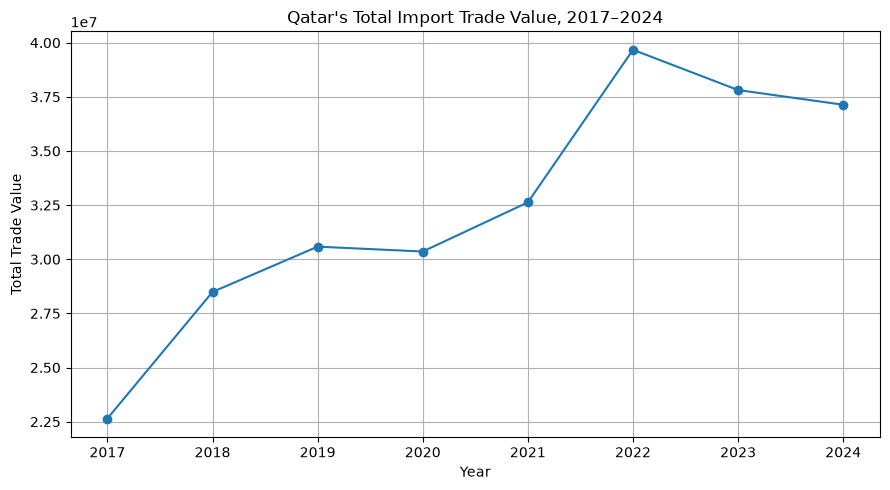

In [70]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    q1_result["year"],
    q1_result["total_trade_value"],
    marker="o"
)

plt.title("Qatar's Total Import Trade Value, 2017–2024")
plt.xlabel("Year")
plt.ylabel("Total Trade Value")
plt.grid(True)

plt.tight_layout()
plt.show()

## Question 2: Qatar's Top Exporting Countries

Which exporting countries had the highest total trade value with Qatar from 2017 to 2024?

In [71]:
q2_result = duckdb.sql("""
    SELECT
        e.exporter_name,
        SUM(f.trade_value) AS total_trade_value
    FROM fact_trade AS f
    JOIN dim_exporter AS e
        ON f.exporter_code = e.exporter_code
    GROUP BY e.exporter_name
    ORDER BY total_trade_value DESC
    LIMIT 10
""")

q2_result

┌──────────────────────┬────────────────────┐
│    exporter_name     │ total_trade_value  │
│       varchar        │       double       │
├──────────────────────┼────────────────────┤
│ China                │  29446689.56700003 │
│ USA                  │ 26697133.705000028 │
│ United Kingdom       │  22096966.94199999 │
│ France               │ 16375844.079999983 │
│ United Arab Emirates │  13320660.64100001 │
│ India                │  13309943.14100004 │
│ Germany              │ 13133309.747000009 │
│ Italy                │  12313490.03100003 │
│ Oman                 │ 10382016.682999983 │
│ Japan                │  9363254.583999999 │
└──────────────────────┴────────────────────┘
  10 rows                         2 columns

In [72]:
q2_chart = q2_result.df()

q2_chart

,exporter_name,total_trade_value
0,China,2.944669e+07
1,USA,2.669713e+07
2,United Kingdom,2.209697e+07
3,France,1.637584e+07
4,United Arab Emirates,1.332066e+07
5,India,1.330994e+07
6,Germany,1.313331e+07
7,Italy,1.231349e+07
8,Oman,1.038202e+07
9,Japan,9.363255e+06


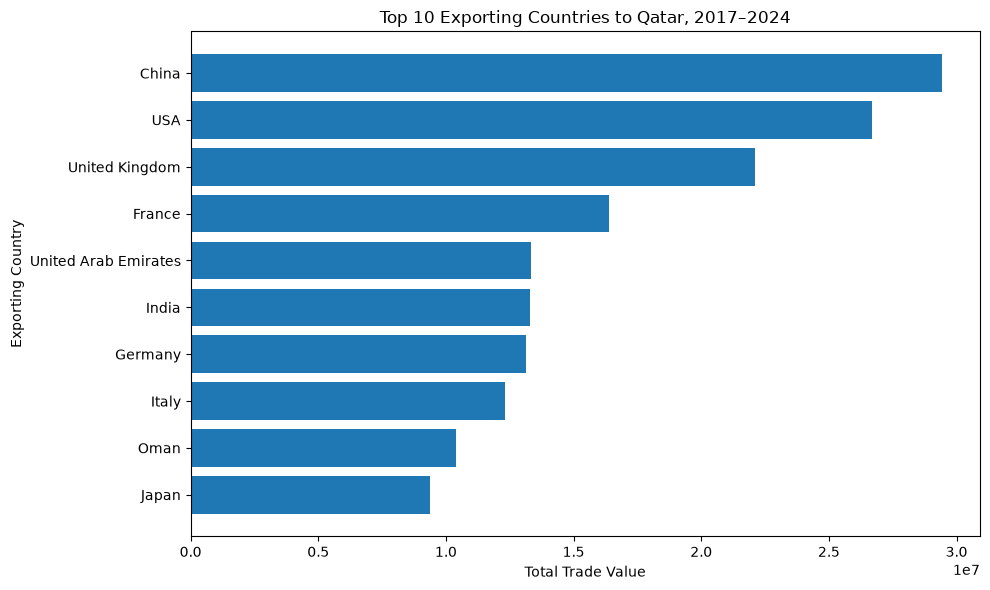

In [73]:
plt.figure(figsize=(10, 6))

plt.barh(
    q2_chart["exporter_name"][::-1],
    q2_chart["total_trade_value"][::-1]
)

plt.title("Top 10 Exporting Countries to Qatar, 2017–2024")
plt.xlabel("Total Trade Value")
plt.ylabel("Exporting Country")

plt.tight_layout()
plt.show()

## Question 3: Qatar's Top Imported Products

Which products had the highest total trade value among Qatar's imports from 2017 to 2024?

In [74]:
q3_result = duckdb.sql("""
    SELECT
        p.product_code,
        p.product_description,
        SUM(f.trade_value) AS total_trade_value
    FROM fact_trade AS f
    JOIN dim_product AS p
        ON f.product_code = p.product_code
    GROUP BY
        p.product_code,
        p.product_description
    ORDER BY total_trade_value DESC
    LIMIT 10
""")

q3_result

┌──────────────┬──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┬────────────────────┐
│ product_code │                                                                                                           product_description                                                                                                            │ total_trade_value  │
│   varchar    │                                                                                                                 varchar                                                                                                                  │       double       │
├──────────────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

In [75]:
q3_chart = q3_result.df()

q3_chart

,product_code,product_description,total_trade_value
0,841112,Turbo-jets: of a thrust exceeding 25kN,1.341201e+07
1,711319,Jewellery: of precious metal (excluding silver...,1.021563e+07
2,880240,Aeroplanes and other aircraft: of an unladen w...,9.334377e+06
3,870324,Vehicles: with only spark-ignition internal co...,5.516226e+06
4,851712,Telephones for cellular networks or for other ...,3.874849e+06
5,880330,Aircraft and spacecraft: parts of aeroplanes o...,3.671757e+06
6,870323,Vehicles: with only spark-ignition internal co...,3.137593e+06
7,710812,"Metals: gold, non-monetary, unwrought (but not...",3.090745e+06
8,300490,Medicaments: consisting of mixed or unmixed pr...,3.080198e+06
9,271000,Petroleum oils and oils from bituminous minera...,2.763942e+06


/var/folders/kd/jz6bv1rs1k989hcql0b_nl2w0000gn/T/ipykernel_12937/2126159032.py:12: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


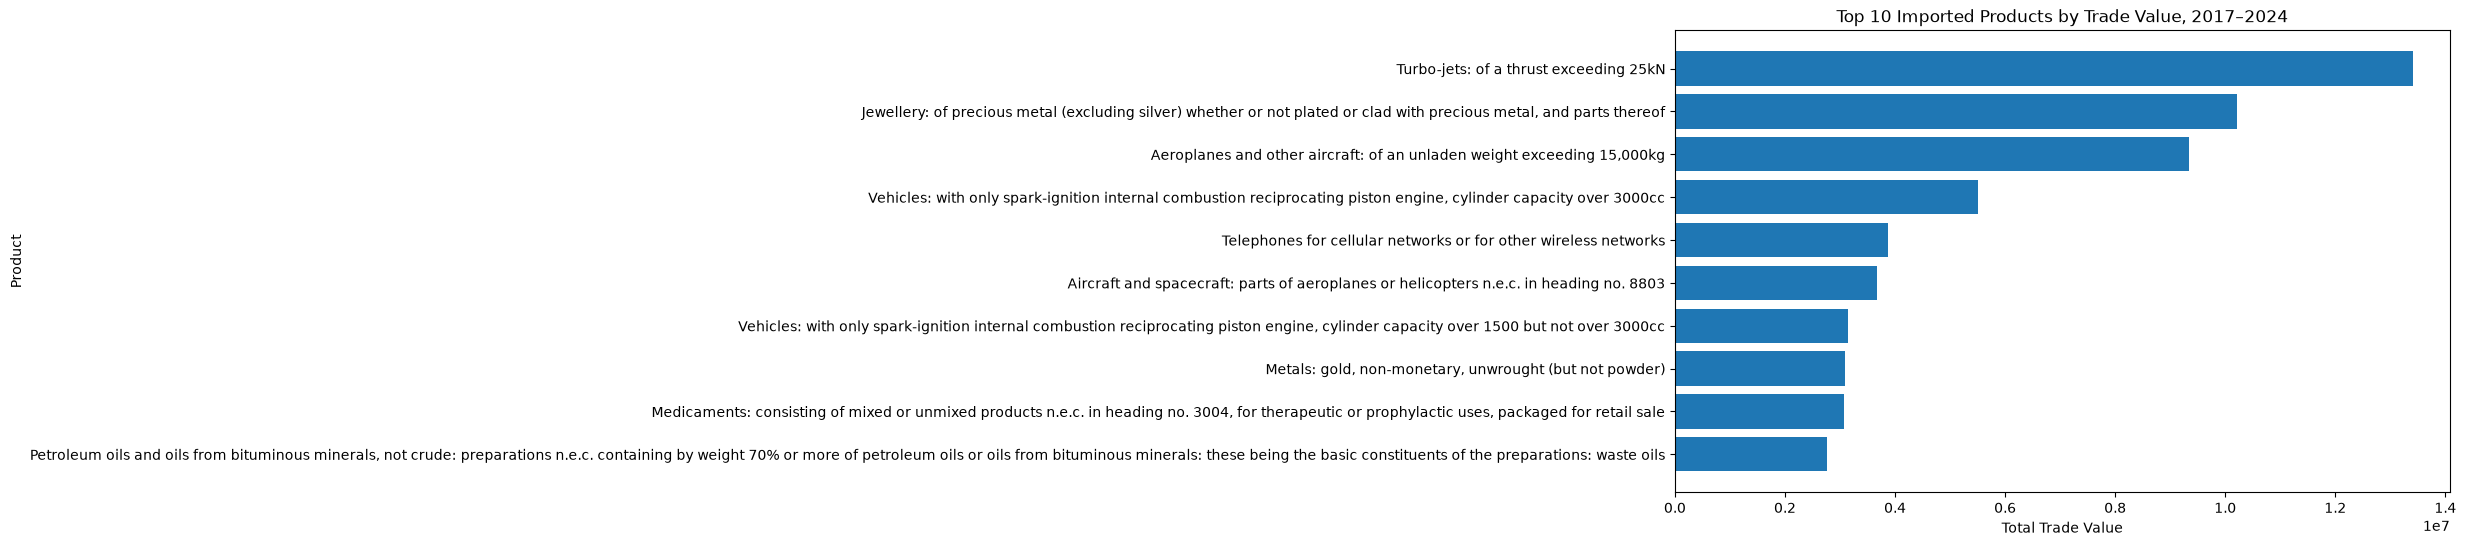

In [76]:
plt.figure(figsize=(10, 6))

plt.barh(
    q3_chart["product_description"][::-1],
    q3_chart["total_trade_value"][::-1]
)

plt.title("Top 10 Imported Products by Trade Value, 2017–2024")
plt.xlabel("Total Trade Value")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

## Question 4: Change in Qatar's Imports by Top Exporters

How did the total import trade value from Qatar's top exporting countries change between 2017 and 2024?

In [77]:
duckdb.sql("""
    WITH top_exporters AS (
        SELECT
            exporter_code,
            SUM(trade_value) AS total_trade_value
        FROM fact_trade
        GROUP BY exporter_code
        ORDER BY total_trade_value DESC
        LIMIT 5
    )

    SELECT
        e.exporter_name,
        f.year,
        SUM(f.trade_value) AS trade_value
    FROM fact_trade AS f
    JOIN dim_exporter AS e
        ON f.exporter_code = e.exporter_code
    JOIN top_exporters AS t
        ON f.exporter_code = t.exporter_code
    WHERE f.year IN (2017, 2024)
    GROUP BY
        e.exporter_name,
        f.year
    ORDER BY
        e.exporter_name,
        f.year
""")

┌──────────────────────┬───────┬────────────────────┐
│    exporter_name     │ year  │    trade_value     │
│       varchar        │ int64 │       double       │
├──────────────────────┼───────┼────────────────────┤
│ China                │  2017 │ 1680216.7099999972 │
│ China                │  2024 │  5235475.052000008 │
│ France               │  2017 │  2232536.075999997 │
│ France               │  2024 │   936499.240999999 │
│ USA                  │  2017 │ 1414257.8309999998 │
│ USA                  │  2024 │  4212746.326999998 │
│ United Arab Emirates │  2024 │         1655440.68 │
│ United Kingdom       │  2017 │ 3105751.5350000034 │
│ United Kingdom       │  2024 │  2350011.318999998 │
└──────────────────────┴───────┴────────────────────┘

In [78]:
q4_chart = duckdb.sql("""
    WITH top_exporters AS (
        SELECT
            exporter_code,
            SUM(trade_value) AS total_trade_value
        FROM fact_trade
        GROUP BY exporter_code
        ORDER BY total_trade_value DESC
        LIMIT 5
    )

    SELECT
        e.exporter_name,
        f.year,
        SUM(f.trade_value) AS trade_value
    FROM fact_trade AS f
    JOIN dim_exporter AS e
        ON f.exporter_code = e.exporter_code
    JOIN top_exporters AS t
        ON f.exporter_code = t.exporter_code
    WHERE f.year IN (2017, 2024)
    GROUP BY
        e.exporter_name,
        f.year
    ORDER BY
        e.exporter_name,
        f.year
""").df()

q4_chart

,exporter_name,year,trade_value
0,China,2017,1680216.710
1,China,2024,5235475.052
2,France,2017,2232536.076
3,France,2024,936499.241
4,USA,2017,1414257.831
5,USA,2024,4212746.327
6,United Arab Emirates,2024,1655440.680
7,United Kingdom,2017,3105751.535
8,United Kingdom,2024,2350011.319


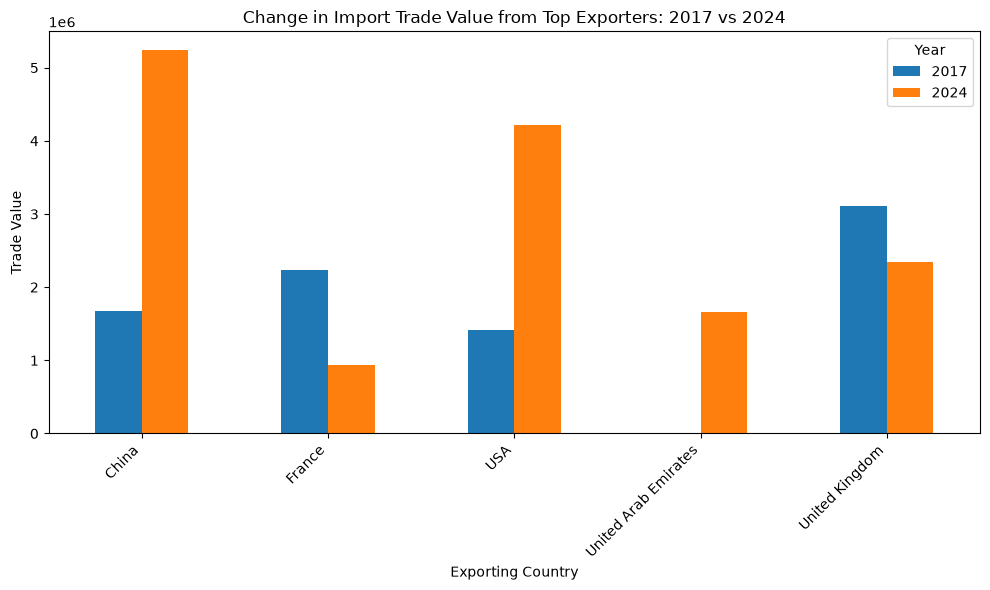

In [79]:
q4_pivot = q4_chart.pivot(
    index="exporter_name",
    columns="year",
    values="trade_value"
)

q4_pivot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Change in Import Trade Value from Top Exporters: 2017 vs 2024")
plt.xlabel("Exporting Country")
plt.ylabel("Trade Value")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Year")

plt.tight_layout()
plt.show()